# 02 – Traitement des images : descriptions + CLIP
**Travail demandé 3** : rendre les images interrogeables.

1. **Description textuelle** de chaque image par un modèle vision local (`qwen3.5:9b`, multimodal, via Ollama), indexée comme du texte.
2. **CLIP** : embedding de l'image elle-même → recherche *texte → image* et *image → image*.

> Prérequis : `ollama pull qwen3.5:9b` et Ollama démarré.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
from src import config
PDF = config.PDF_DIR / "ABB_ACS580_Guide_Variateur.pdf"
print("Projet :", ROOT, "| PDF existe :", PDF.exists())

Projet : c:\Users\OMEN\Downloads\parti 1 projet agent | PDF existe : True


In [2]:
from src.ingestion import parse_pdf, save_elements, slugify
from src.indexer import describe_images
elements = parse_pdf(PDF)
describe_images(elements)   # ~10-30 s par image la première fois (mis en cache ensuite)
save_elements(elements, slugify(PDF.name))
imgs = [e for e in elements if e.type == 'image']

c:\Users\OMEN\Downloads\parti 1 projet agent\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[   0%] Description de l'image 1/8 (page 1) avec qwen3.5:9b
[  12%] Description de l'image 2/8 (page 4) avec qwen3.5:9b
[  25%] Description de l'image 3/8 (page 5) avec qwen3.5:9b
[  38%] Description de l'image 4/8 (page 6) avec qwen3.5:9b
[  50%] Description de l'image 5/8 (page 7) avec qwen3.5:9b
[  62%] Description de l'image 6/8 (page 9) avec qwen3.5:9b
[  75%] Description de l'image 7/8 (page 12) avec qwen3.5:9b
[  88%] Description de l'image 8/8 (page 15) avec qwen3.5:9b


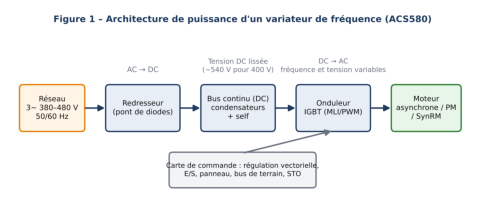

Page 1 : Il s’agit d’un logigramme schématique illustrant l’architecture de puissance d’un variateur de fréquence ABB ACS580,
présentant les étapes de conversion AC→DC puis DC→AC avec leurs composants clés : réseau triphasé 3~ 380–480 V à 50/60
Hz, redresseur (pont de diodes), bus continu (~540 V pour 400 V) avec condensateurs et self, onduleur IGBT (MLI/PWM), et
moteur asynchrone / PM / SynRM. La carte de commande associée gère la régulation vectorielle, les entrées/sorties, le
panneau, le bus de terrain et le STO. Ce document sert à comprendre le flux énergétique interne du variateur pour
faciliter le diagnostic des pannes, la maintenance préventive ou l’analyse des défauts liés aux composants de puissance.
Il ne remplace pas les manuels officiels ABB avant toute intervention réelle. 



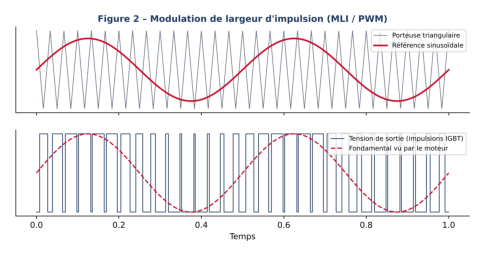

Page 4 : Graphique illustrant la modulation de largeur d’impulsion (MLI/PWM) dans un variateur ABB ACS580, montrant en haut une
porteuse triangulaire grise et une référence sinusoïdale rouge, et en bas les impulsions de tension de sortie bleues
issues des IGBT ainsi que l’onde fondamentale vue par le moteur en pointillés rouges ; les axes indiquent le temps de
0.0 à 1.0 sans unité explicite mais correspondant à un cycle normalisé ; ce graphique explique comment la comparaison
entre la référence et la porteuse génère une tension moyenne sinusoïdale perçue par le moteur inductif, permettant au
variateur de contrôler précisément la vitesse et le couple tout en limitant les harmoniques grâce à la commutation
rapide des IGBT. 



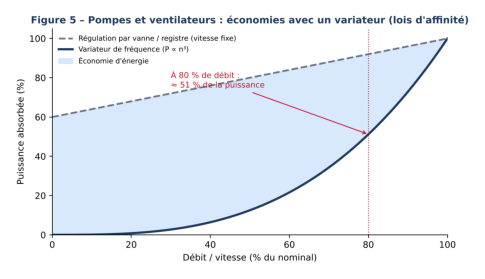

Page 5 : Il s’agit d’un graphique comparatif illustrant l’économie d’énergie réalisée avec un variateur de fréquence selon la loi
d’affinité, par rapport à une régulation par vanne ou registre à vitesse fixe. Les axes représentent le débit/vitesse en
% du nominal (abscisse) et la puissance absorbée en % (ordonnée). Deux courbes sont tracées : une ligne pointillée grise
pour la régulation par vanne (puissance croissant linéairement de 60 % à 100 %) et une courbe bleue foncée pour le
variateur de fréquence (puissance suivant P ∝ n³, passant de 0 % à 100 %). Une zone ombrée bleu clair indique l’économie
d’énergie entre les deux modes. Un repère vertical rouge à 80 % de débit montre que la puissance absorbée est alors ≈ 51
%, contre ≈ 92 % avec vanne. Le graphique permet aux techniciens de quantifier les gains énergétiques en fonction du
point de fonctionnement, notamment pour justifier l’installation ou le réglage d’un variateur ABB ACS580 dans des
systèmes de pompage ou ventilation. 



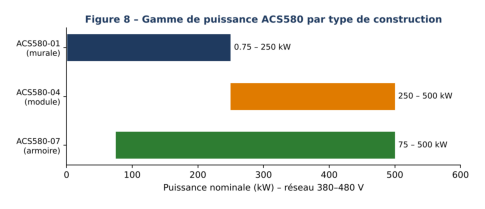

Page 6 : Il s’agit d’un graphique à barres horizontales illustrant la gamme de puissance nominale (en kW) des variateurs ABB
ACS580 selon leur type de construction : murale (ACS580-01), module (ACS580-04) et armoire (ACS580-07). Les valeurs
affichées sont 0,75–250 kW pour le modèle mural, 250–500 kW pour le module, et 75–500 kW pour l’armoire, toutes sur
réseau 380–480 V. Ce graphique permet aux techniciens de maintenance d’identifier rapidement la plage de puissance
associée à chaque configuration mécanique du variateur, ce qui influence directement les procédures d’accès aux
composants (ventilateurs, radiateurs), les intervalles de remplacement des pièces d’usure et le choix des outils ou
équipements nécessaires lors des interventions. La lecture des codes de référence mentionnés dans le contexte textuel
complète cette information en reliant la puissance à la désignation exacte du modèle, facilitant ainsi la traçabilité et
la conformité des actions de maintenance. 



In [3]:
import matplotlib.pyplot as plt
from PIL import Image
import textwrap
for e in imgs[:4]:
    plt.figure(figsize=(6, 3.5)); plt.imshow(Image.open(config.abs_path(e.image_path))); plt.axis('off'); plt.show()
    print(f'Page {e.page} :', textwrap.fill(e.content, 120), '\n')

## CLIP : similarité texte → image
Chaque ligne = une requête en français, chaque colonne = une image. On utilise l'encodeur texte **CLIP multilingue**, aligné sur l'encodeur image CLIP ViT-B/32.

In [4]:
import numpy as np, pandas as pd
from src.embeddings import get_clip_embedder
clip = get_clip_embedder()
img_vecs = clip.embed_images([e.image_path for e in imgs])
queries = ['schéma électrique de câblage des bornes', 'organigramme de dépannage', 'panneau de commande avec boutons', 'courbe de puissance et économie d énergie', 'calendrier de maintenance']
q = np.stack([clip.embed_text(t) for t in queries])
sim = q @ img_vecs.T
pd.DataFrame(sim, index=queries, columns=[f'p{e.page}' for e in imgs]).style.background_gradient(axis=1).format('{:.3f}')

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 414.24it/s]


,p1,p4,p5,p6,p7,p9,p12,p15
schéma électrique de câblage des bornes,0.233,0.238,0.210,0.222,0.197,0.230,0.225,0.209
organigramme de dépannage,0.211,0.207,0.211,0.190,0.203,0.214,0.214,0.206
panneau de commande avec boutons,0.224,0.183,0.164,0.184,0.246,0.219,0.199,0.201
courbe de puissance et économie d énergie,0.228,0.251,0.255,0.252,0.197,0.225,0.226,0.222
calendrier de maintenance,0.220,0.198,0.202,0.208,0.217,0.245,0.219,0.244


## CLIP : recherche image → image
On simule la photo d'un technicien en recadrant/assombrissant une image du manuel.

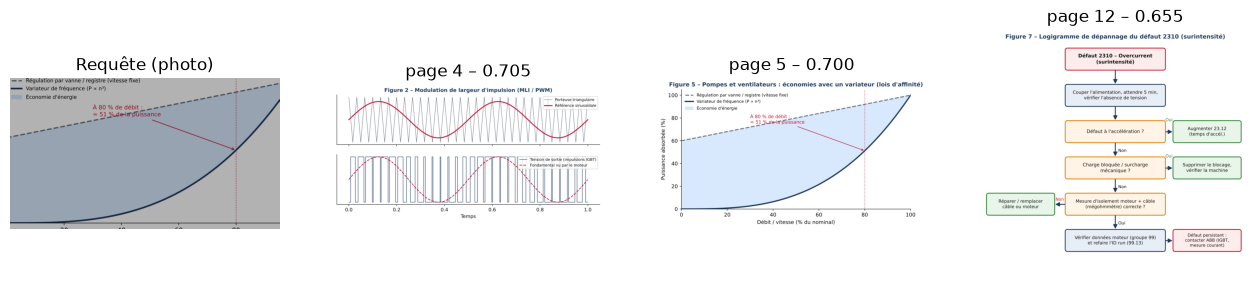

In [ ]:
from PIL import ImageEnhance
src_img = Image.open(config.abs_path(imgs[2].image_path))
w, h = src_img.size
photo = ImageEnhance.Brightness(src_img.crop((int(w*.1), int(h*.1), int(w*.9), int(h*.9)))).enhance(0.7)

pv = clip.embed_pil([photo])[0]
scores = img_vecs @ pv
best = np.argsort(-scores)[:3]
fig, axs = plt.subplots(1, 4, figsize=(16, 4))
axs[0].imshow(photo); axs[0].set_title('Requête (photo)')
for ax, i in zip(axs[1:], best):
    ax.imshow(Image.open(config.abs_path(imgs[i].image_path))); ax.set_title(f'page {imgs[i].page} – {scores[i]:.3f}')
for ax in axs: ax.axis('off')
plt.show()